# Cas d'étude : prédiction du churn — Exploration et modélisation

Notebook Data Science du projet `ml-churn-project`.

**Problème** : prédire si un client d'un opérateur télécom va résilier son abonnement (*churn*).
**Variable cible** : `churn` (0 = reste, 1 = part) → **classification binaire supervisée**.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
df = pd.read_csv(ROOT / 'data' / 'raw' / 'churn.csv')
df.head()

,age,anciennete,revenu,nb_reclamations,montant_mensuel,retards_paiement,churn
0,56,93,407324,2,35104,3,0
1,69,64,869449,0,42594,1,0
2,46,44,904651,3,8664,2,0
3,32,53,808681,4,15528,2,0
4,60,24,580599,4,33190,1,1


## 1. Structure du jeu de données

In [2]:
print('Dimensions :', df.shape)
print()
print(df.dtypes)
print()
print('Valeurs manquantes :')
print(df.isnull().sum())

Dimensions : (2000, 7)

age                 int64
anciennete          int64
revenu              int64
nb_reclamations     int64
montant_mensuel     int64
retards_paiement    int64
churn               int64
dtype: object

Valeurs manquantes :
age                 0
anciennete          0
revenu              0
nb_reclamations     0
montant_mensuel     0
retards_paiement    0
churn               0
dtype: int64


In [3]:
df.describe().round(2)

,age,anciennete,revenu,nb_reclamations,montant_mensuel,retards_paiement,churn
count,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00
mean,43.81,58.78,583363.92,1.95,38699.85,1.01,0.43
std,14.93,34.80,244511.53,1.32,20235.28,1.01,0.50
min,18.00,1.00,150159.00,0.00,5005.00,0.00,0.00
25%,31.00,28.00,372126.75,1.00,21335.50,0.00,0.00
50%,44.00,58.00,580185.50,2.00,38165.50,1.00,0.00
75%,56.00,89.00,797360.25,3.00,56366.50,2.00,1.00
max,69.00,119.00,999776.00,8.00,74963.00,6.00,1.00


## 2. Variable cible

Le jeu est **légèrement déséquilibré** (≈ 57 % / 43 %) : l'accuracy seule ne suffit pas, on suivra aussi precision, recall, F1 et ROC-AUC. Le split train/test est **stratifié** pour conserver cette proportion.

churn
0    1139
1     861
Name: count, dtype: int64
churn
0    0.57
1    0.43
Name: proportion, dtype: float64


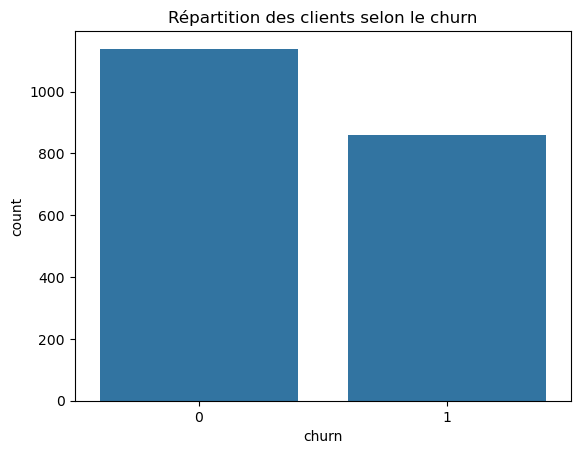

In [4]:
print(df['churn'].value_counts())
print(df['churn'].value_counts(normalize=True).round(3))
sns.countplot(data=df, x='churn')
plt.title('Répartition des clients selon le churn')
plt.show()

## 3. Corrélations

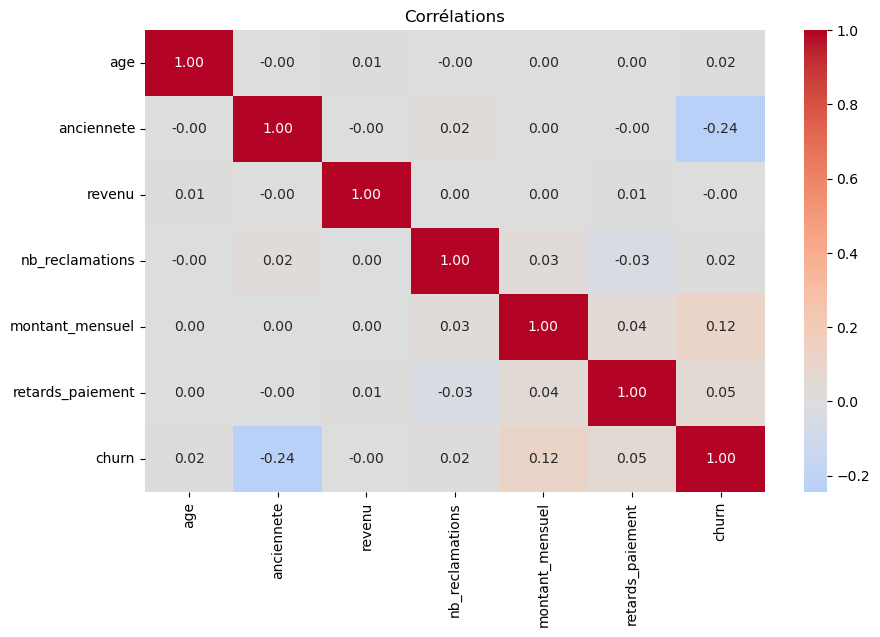

In [5]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Corrélations')
plt.show()

## 4. Variables selon le churn

L'**ancienneté** est le facteur le plus discriminant (les clients récents partent plus), suivie du **montant mensuel**. `age` et `revenu` n'ont pas d'effet (ils n'interviennent pas dans le mécanisme de génération).

In [6]:
df.groupby('churn').mean().round(2).T

churn,0,1
age,43.60,44.08
anciennete,66.18,48.99
revenu,583472.46,583220.32
nb_reclamations,1.93,1.97
montant_mensuel,36660.50,41397.67
retards_paiement,0.97,1.07


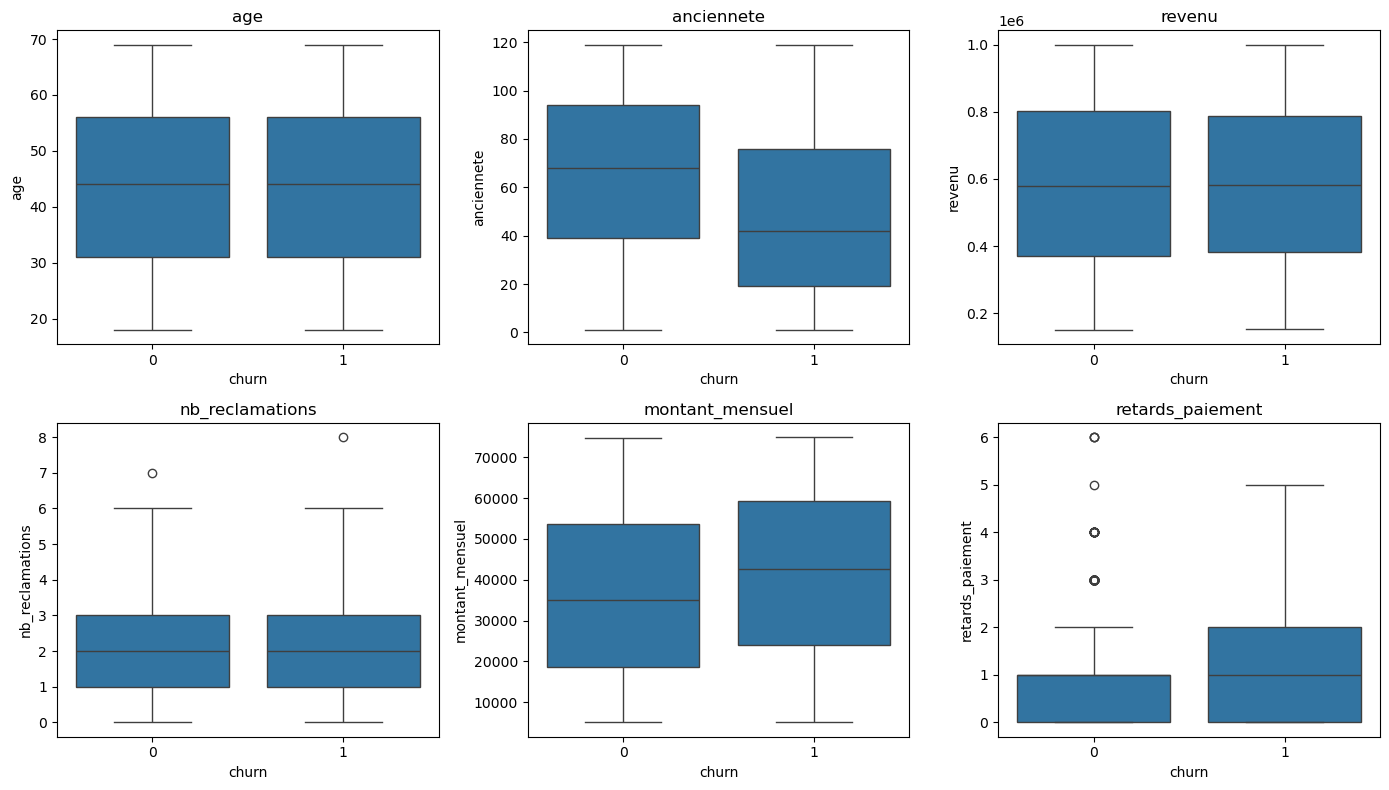

In [7]:
features = [c for c in df.columns if c != 'churn']
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(data=df, x='churn', y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 5. Comparaison des modèles

Même protocole que `src/train.py` : split 80/20 stratifié, `random_state=42`.

In [8]:
import sys
sys.path.insert(0, str(ROOT))
from sklearn.model_selection import train_test_split
from src.train import FEATURES, TARGET, build_models, evaluate

X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

results = {}
models = build_models()
for name, model in models.items():
    model.fit(X_train, y_train)
    results[name] = evaluate(model, X_test, y_test)
pd.DataFrame(results).T

,accuracy,precision,recall,f1,roc_auc
logistic_regression,0.6250,0.5821,0.4535,0.5098,0.6364
decision_tree,0.6325,0.5828,0.5116,0.5449,0.6233
random_forest,0.6000,0.5435,0.4360,0.4839,0.6246


## 6. Importance des variables (Random Forest)

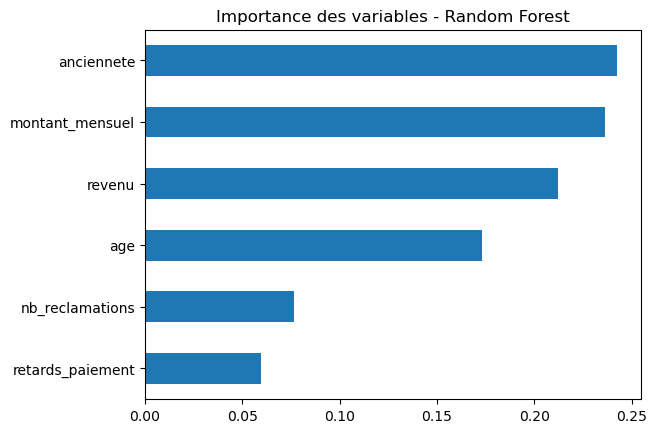

In [9]:
rf = models['random_forest']
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
imp.plot.barh(title='Importance des variables - Random Forest')
plt.show()

## 7. Conclusion

- Le signal est **faible** par construction (données synthétiques bruitées) : ROC-AUC ≈ 0,62–0,64 pour les trois modèles.
- La **régression logistique** obtient la meilleure ROC-AUC : c'est cohérent, puisque les données sont générées par une fonction logistique.
- Le **Random Forest** est retenu pour la suite du TP (consigne du sujet). C'est un modèle robuste, non linéaire, peu sensible à l'échelle des variables et qui fournit des probabilités. Le script `src/train.py --model` permet de déployer un autre modèle sans modifier l'API.
- Pistes d'amélioration : limiter la profondeur des arbres (sur-apprentissage), validation croisée, recherche d'hyperparamètres et ajustement du seuil de décision selon le coût métier d'un churn non détecté.